<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/Assignments/zhiyuguo_innis_Case_Study_Assignment2_Internet_Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case 2: Adventure Works Internet Sales

**Student:** Zhiyu Guo · MSSP 607, University of Pennsylvania
**Dataset:** *Internet Sales* extract of the Adventure Works sample database (Microsoft Corporation). Fictitious data, used for learning purposes only.



## 1. Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Chart colours (validated colour-blind-safe categorical palette)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
YEAR_BLUES = ['#a9c9f0', '#5b9ae3', '#1f5fae']      # 2011, 2012, 2013: light -> dark
GREY_TEXT, GRID = '#52514e', '#e5e5e2'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 12})
os.makedirs('figures', exist_ok=True)
def fmt_p(p):
    return '< .001' if p < 0.001 else f'= {p:.3f}'

usd = FuncFormatter(lambda v, _: f'${v/1e6:g}M')          # millions axis, e.g. $1.5M
usd_plain = FuncFormatter(lambda v, _: f'${v:,.0f}')       # dollars axis, e.g. $2,500

The CSV is stored in my GitHub repository and read through its *raw* URL.
The file is encoded in Windows-1252/Latin-1 (some city names contain accented letters such as "ó"),
so `encoding='latin-1'` is required; reading it as UTF-8 raises a `UnicodeDecodeError`.

In [ ]:
DATA_URL = 'https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/InternetSales.csv'
LOCAL_COPY = 'InternetSales.csv'   # only used if GitHub cannot be reached

try:
    sales = pd.read_csv(DATA_URL, encoding='latin-1', low_memory=False)
    print('Loaded from GitHub:', DATA_URL)
except Exception as err:
    print('GitHub read failed (', type(err).__name__, ') - reading local copy instead.')
    sales = pd.read_csv(LOCAL_COPY, encoding='latin-1', low_memory=False)

print('Shape:', sales.shape)
sales[['SalesOrderNumber', 'OrderDate', 'EnglishCountryRegionName',
       'EnglishProductName', 'UnitPrice', 'SalesAmount']].head()

Loaded from GitHub: https://raw.githubusercontent.com/zhiyuguo-innis/MSSP607/main/data/InternetSales.csv
Shape: (60398, 60)


,SalesOrderNumber,OrderDate,EnglishCountryRegionName,EnglishProductName,UnitPrice,SalesAmount
0,SO43793,1/19/2011,Australia,"Mountain-100 Silver, 38","3,399.99","3,399.99"
1,SO51522,1/18/2013,Australia,"Mountain-200 Silver, 38","2,319.99","2,319.99"
2,SO51522,1/18/2013,Australia,Fender Set - Mountain,21.98,21.98
3,SO57418,5/3/2013,Australia,"Touring-1000 Blue, 46","2,384.07","2,384.07"
4,SO57418,5/3/2013,Australia,Touring Tire,28.99,28.99


## 2. Data preparation and quality checks

In [ ]:
# Columns that carry no information
empty_cols = [c for c in sales.columns if sales[c].isna().all()]
constant_cols = [c for c in sales.columns if sales[c].nunique(dropna=True) == 1]
print('Entirely empty columns :', empty_cols)
print('Single-value columns   :', constant_cols)

# Mostly-missing columns (personal-name fields, not used in the analysis)
missing = sales.isna().mean().sort_values(ascending=False)
print('\nShare missing (columns with any missing values):')
print(missing[missing > 0].round(3))

print('\nDuplicate rows:', sales.duplicated().sum())
print('CustomerKey == CustomerKey.1 on every row:', (sales['CustomerKey'] == sales['CustomerKey.1']).all())
print('Unique customers:', sales['CustomerKey'].nunique(), '| unique orders:', sales['SalesOrderNumber'].nunique())

Entirely empty columns : ['CarrierTrackingNumber', 'CustomerPONumber']
Single-value columns   : ['NameStyle', 'Suffix', 'RevisionNumber', 'OrderQuantity', 'UnitPriceDiscountPct', 'DiscountAmount']

Share missing (columns with any missing values):
CustomerPONumber        1.00
CarrierTrackingNumber   1.00
Suffix                  1.00
Title                   0.99
AddressLine2            0.98
MiddleName              0.42
dtype: float64

Duplicate rows: 0
CustomerKey == CustomerKey.1 on every row: True
Unique customers: 18484 | unique orders: 27659


Every row is one order line. `OrderQuantity` is always 1 and `DiscountAmount` is always 0, so
`SalesAmount` equals `UnitPrice` on every row and each row is one unit sold.
The two empty columns (`CarrierTrackingNumber`, `CustomerPONumber`) and the duplicate key column are dropped.

In [ ]:
sales = sales.drop(columns=empty_cols + ['CustomerKey.1'])
print('SalesAmount equals UnitPrice on every row:', np.allclose(sales['SalesAmount'], sales['UnitPrice']))

for col in ['OrderDate', 'ShipDate', 'DueDate', 'BirthDate', 'DateFirstPurchase']:
    sales[col] = pd.to_datetime(sales[col], format='%m/%d/%Y')
sales['OrderYear'] = sales['OrderDate'].dt.year
sales['Margin'] = sales['SalesAmount'] - sales['TotalProductCost']

coverage = sales.groupby('OrderYear')['OrderDate'].agg(first_order='min', last_order='max', order_lines='count')
coverage

SalesAmount equals UnitPrice on every row: True


,first_order,last_order,order_lines
OrderYear,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


**Partial years.** 2010 covers only 29–31 December and 2014 only 1–28 January (and contains no bike sales),
so year-over-year comparisons use the three complete years, 2011–2013.

**Product category.** The extract has no category column, only `EnglishProductName`. I rebuilt the standard
Adventure Works hierarchy (category → subcategory) from the product names. The rule below maps all 130 products,
and the check confirms that none is left unmapped.

In [ ]:
BIKE_LINES = {'Mountain': 'Mountain Bikes', 'Road': 'Road Bikes', 'Touring': 'Touring Bikes'}
KEYWORDS = [('Helmet', 'Helmets'), ('Bottle Cage', 'Bottles and Cages'), ('Water Bottle', 'Bottles and Cages'),
            ('Tire', 'Tires and Tubes'), ('Tube', 'Tires and Tubes'), ('Patch Kit', 'Tires and Tubes'),
            ('Fender', 'Fenders'), ('Hitch Rack', 'Bike Racks'), ('Bike Stand', 'Bike Stands'),
            ('Bike Wash', 'Cleaners'), ('Hydration Pack', 'Hydration Packs'),
            ('Cap', 'Caps'), ('Gloves', 'Gloves'), ('Jersey', 'Jerseys'), ('Shorts', 'Shorts'),
            ('Socks', 'Socks'), ('Vest', 'Vests')]
CLOTHING = {'Caps', 'Gloves', 'Jerseys', 'Shorts', 'Socks', 'Vests'}

def subcategory(name):
    model = name.split(',')[0]                      # e.g. 'Mountain-200 Black'
    line = model.split('-')[0]
    if line in BIKE_LINES and any(ch.isdigit() for ch in model):
        return BIKE_LINES[line]
    for key, sub in KEYWORDS:
        if key in name:
            return sub
    return 'UNMAPPED'

sales['Subcategory'] = sales['EnglishProductName'].map(subcategory)
sales['Category'] = np.select([sales['Subcategory'].str.endswith('Bikes'), sales['Subcategory'].isin(CLOTHING)],
                              ['Bikes', 'Clothing'], default='Accessories')
sales['Model'] = sales['EnglishProductName'].str.split(',').str[0].str.replace(
    r' (Black|Silver|Red|Yellow|Blue)$', '', regex=True)

print('Unmapped products:', (sales['Subcategory'] == 'UNMAPPED').sum())
sales.groupby(['Category', 'Subcategory']).agg(products=('EnglishProductName', 'nunique'),
                                                order_lines=('SalesAmount', 'size'))

Unmapped products: 0


products  order_lines
Category    Subcategory                             
Accessories Bike Racks                1          328
            Bike Stands               1          249
            Bottles and Cages         3         7981
            Cleaners                  1          908
            Fenders                   1         2121
            Helmets                   3         6440
            Hydration Packs           1          733
            Tires and Tubes          11        17332
Bikes       Mountain Bikes           28         4970
            Road Bikes               38         8068
            Touring Bikes            22         2167
Clothing    Caps                      1         2190
            Gloves                    3         1430
            Jerseys                   8         3332
            Shorts                    3         1019
            Socks                     2          568
            Vests                     3          562

Most questions are about customers, not order lines. A customer who buys 16 times appears 16 times in the
line-level data, so customer attributes (income, gender, home ownership) are summarised on a **customer-level table**
with one row per customer.

In [ ]:
customers = (sales.groupby('CustomerKey')
             .agg(Country=('EnglishCountryRegionName', 'first'), Gender=('Gender', 'first'),
                  YearlyIncome=('YearlyIncome', 'first'), HouseOwner=('HouseOwnerFlag', 'first'),
                  TotalChildren=('TotalChildren', 'first'), CarsOwned=('NumberCarsOwned', 'first'),
                  MaritalStatus=('MaritalStatus', 'first'), Education=('EnglishEducation', 'first'),
                  Revenue=('SalesAmount', 'sum'), Orders=('SalesOrderNumber', 'nunique'),
                  BikesBought=('Category', lambda s: (s == 'Bikes').sum()),
                  FirstOrder=('OrderDate', 'min'))
             .reset_index())
customers['BikeBuyer'] = customers['BikesBought'] > 0

# Customer attributes are fixed per customer in the source table - confirm before relying on 'first'
attrs = ['EnglishCountryRegionName', 'Gender', 'YearlyIncome', 'HouseOwnerFlag']
print('Max distinct values per customer:', sales.groupby('CustomerKey')[attrs].nunique().max().max())
print('Customers:', len(customers))
customers.head()

Max distinct values per customer: 1
Customers: 18484


,CustomerKey,Country,Gender,YearlyIncome,HouseOwner,TotalChildren,CarsOwned,MaritalStatus,Education,Revenue,Orders,BikesBought,FirstOrder,BikeBuyer
0,11000,Australia,M,90000,1,2,0,M,Bachelors,"8,248.99",3,3,2011-01-19,True
1,11001,Australia,M,60000,0,3,1,S,Bachelors,"6,383.88",3,3,2011-01-15,True
2,11002,Australia,M,60000,1,3,1,M,Bachelors,"8,114.04",3,3,2011-01-07,True
3,11003,Australia,F,70000,0,0,1,S,Bachelors,"8,139.29",3,3,2010-12-29,True
4,11004,Australia,F,80000,1,5,4,S,Bachelors,"8,196.01",3,3,2011-01-23,True


## 3. Question 1 - Internet sales by year for each Country Region

I summed `SalesAmount` by customer country and order year.

In [ ]:
q1 = sales.pivot_table(index='EnglishCountryRegionName', columns='OrderYear', values='SalesAmount',
                       aggfunc='sum', fill_value=0, margins=True, margins_name='Total')
q1.index.name, q1.columns.name = 'Country Region', 'Order year'
q1 = q1.sort_values('Total', ascending=False)
q1.round(0)

Order year,2010,2011,2012,2013,2014,Total
Country Region,,,,,,
Total,"43,421.00","7,075,526.00","5,842,485.00","16,351,550.00","45,695.00","29,358,677.00"
United States,"14,834.00","2,458,285.00","1,437,049.00","5,462,079.00","17,543.00","9,389,790.00"
Australia,"20,910.00","2,563,732.00","2,128,407.00","4,339,443.00","8,508.00","9,061,001.00"
United Kingdom,699.00,"550,591.00","712,701.00","2,124,007.00","3,714.00","3,391,712.00"
Germany,0.00,"520,500.00","608,658.00","1,761,876.00","3,278.00","2,894,312.00"
France,"3,400.00","410,845.00","648,066.00","1,578,512.00","3,195.00","2,644,018.00"
Canada,"3,578.00","571,572.00","307,605.00","1,085,633.00","9,458.00","1,977,845.00"


In [ ]:
full = q1.drop(index='Total')[[2011, 2012, 2013]]
q1_growth = pd.DataFrame({
    'Share of total sales (%)': q1.drop(index='Total')['Total'] / q1.loc['Total', 'Total'] * 100,
    'Change 2011->2012 (%)': (full[2012] / full[2011] - 1) * 100,
    'Change 2012->2013 (%)': (full[2013] / full[2012] - 1) * 100,
    '2013 sales / 2012 sales (x)': full[2013] / full[2012],
    '2013 sales / 2011 sales (x)': full[2013] / full[2011],
})
total_row = q1.loc['Total']
print(f"All countries: 2011 ${total_row[2011]:,.0f} | 2012 ${total_row[2012]:,.0f} "
      f"({(total_row[2012]/total_row[2011]-1)*100:+.1f}%) | 2013 ${total_row[2013]:,.0f} "
      f"({(total_row[2013]/total_row[2012]-1)*100:+.1f}%)")
q1_growth.round(1)

All countries: 2011 $7,075,526 | 2012 $5,842,485 (-17.4%) | 2013 $16,351,550 (+179.9%)


,Share of total sales (%),Change 2011->2012 (%),Change 2012->2013 (%),2013 sales / 2012 sales (x),2013 sales / 2011 sales (x)
Country Region,,,,,
United States,32.00,-41.50,280.10,3.80,2.20
Australia,30.90,-17.00,103.90,2.00,1.70
United Kingdom,11.60,29.40,198.00,3.00,3.90
Germany,9.90,16.90,189.50,2.90,3.40
France,9.00,57.70,143.60,2.40,3.80
Canada,6.70,-46.20,252.90,3.50,1.90


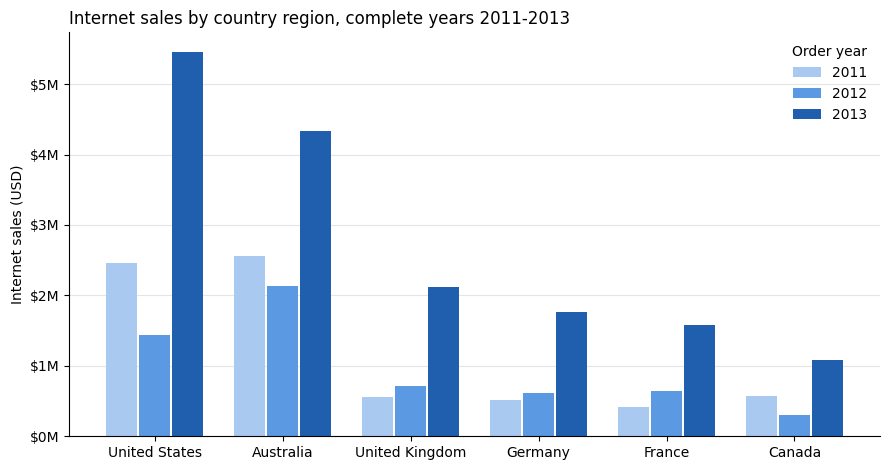

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
order = full.sum(axis=1).sort_values(ascending=False).index
x = np.arange(len(order)); w = 0.26
for i, (yr, col) in enumerate(zip([2011, 2012, 2013], YEAR_BLUES)):
    ax.bar(x + (i - 1) * w, full.loc[order, yr], width=w - 0.02, color=col, label=str(yr))
ax.set_xticks(x, order)
ax.yaxis.set_major_formatter(usd)
ax.set_ylabel('Internet sales (USD)')
ax.set_title('Internet sales by country region, complete years 2011-2013')
ax.grid(axis='x', visible=False)
ax.legend(title='Order year', frameon=False)
fig.tight_layout()
fig.savefig('figures/fig1_sales_country_year.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Question 2 - Yearly Income summary statistics by Gender and Country Region

Statistics are computed on the customer-level table (each customer counted once).
`YearlyIncome` is recorded in bands of $10,000 (16 distinct values from $10,000 to $170,000).

In [ ]:
q2 = (customers.groupby(['Country', 'Gender'])['YearlyIncome']
      .agg(Customers='count', Mean='mean', Median='median', Min='min', Max='max', SD='std'))
q2_country = customers.groupby('Country')['YearlyIncome'].agg(
    Customers='count', Mean='mean', Median='median', Min='min', Max='max', SD='std')
q2_country.index = pd.MultiIndex.from_product([q2_country.index, ['All']], names=['Country', 'Gender'])
q2_all = pd.concat([q2, q2_country]).sort_index()
overall = customers['YearlyIncome'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
print('All customers:', dict(overall.round(0)))
q2_all.round(0)

All customers: {'count': np.float64(18484.0), 'mean': np.float64(57306.0), 'median': np.float64(60000.0), 'min': np.float64(10000.0), 'max': np.float64(170000.0), 'std': np.float64(32286.0)}


Customers      Mean    Median    Min     Max        SD
Country        Gender                                                        
Australia      All          3591 64,339.00 70,000.00  10000  170000 31,830.00
               F            1777 65,284.00 70,000.00  10000  160000 31,164.00
               M            1814 63,412.00 70,000.00  10000  170000 32,451.00
Canada         All          1571 57,167.00 60,000.00  10000  170000 20,252.00
               F             767 56,506.00 60,000.00  10000  170000 19,182.00
               M             804 57,799.00 60,000.00  10000  170000 21,215.00
France         All          1810 35,762.00 30,000.00  10000  110000 27,277.00
               F             893 35,342.00 30,000.00  10000  110000 26,916.00
               M             917 36,172.00 30,000.00  10000  110000 27,633.00
Germany        All          1780 42,944.00 30,000.00  10000  130000 35,494.00
               F             874 43,810.00 30,000.00  10000  130000 35,716.00
               M             906 42,108.00 30,000.00  10000  130000 35,277.00
United Kingdom All          1913 52,169.00 30,000.00  10000  170000 48,432.00
               F             934 52,184.00 30,000.00  10000  170000 48,288.00
               M             979 52,155.00 30,000.00  10000  170000 48,593.00
United States  All          7819 63,617.00 60,000.00  10000  170000 25,706.00
               F            3888 63,277.00 60,000.00  10000  170000 25,167.00
               M            3931 63,953.00 60,000.00  10000  170000 26,228.00

In [ ]:
# Is income different across countries, and between genders?
groups = [g['YearlyIncome'].values for _, g in customers.groupby('Country')]
F, p_country = stats.f_oneway(*groups)
grand = customers['YearlyIncome'].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((customers['YearlyIncome'] - grand) ** 2).sum()
print(f'Income across countries: ANOVA F = {F:,.1f}, p {fmt_p(p_country)}, eta squared = {ss_between/ss_total:.3f}')

def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

rows = []
for country, g in customers.groupby('Country'):
    m, f = g.loc[g.Gender == 'M', 'YearlyIncome'], g.loc[g.Gender == 'F', 'YearlyIncome']
    t = stats.ttest_ind(m, f, equal_var=False)
    rows.append({'Country': country, 'Male mean': m.mean(), 'Female mean': f.mean(),
                 'Difference (M-F)': m.mean() - f.mean(), "Welch p": t.pvalue, "Cohen's d": cohens_d(m, f)})
gender_gap = pd.DataFrame(rows).set_index('Country')
gender_gap.round(3)

Income across countries: ANOVA F = 368.5, p < .001, eta squared = 0.091


,Male mean,Female mean,Difference (M-F),Welch p,Cohen's d
Country,,,,,
Australia,"63,412.35","65,284.19","-1,871.84",0.08,-0.06
Canada,"57,798.51","56,505.87","1,292.64",0.20,0.06
France,"36,172.30","35,341.54",830.76,0.52,0.03
Germany,"42,108.17","43,810.07","-1,701.90",0.31,-0.05
United Kingdom,"52,155.26","52,184.15",-28.89,0.99,-0.00
United States,"63,953.19","63,276.75",676.44,0.24,0.03


In [ ]:
# Line-level version (each order line counted) for comparison: heavy buyers weigh more here
q2_lines = sales.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])
q2_lines.round(0)

count      mean    min     max       std
EnglishCountryRegionName Gender                                          
Australia                F        6685 67,061.00  10000  160000 30,614.00
                         M        6660 65,413.00  10000  170000 32,551.00
Canada                   F        3648 58,651.00  10000  170000 19,435.00
                         M        3972 61,460.00  10000  170000 22,703.00
France                   F        2781 39,367.00  10000  110000 28,422.00
                         M        2777 39,806.00  10000  110000 28,666.00
Germany                  F        2820 48,287.00  10000  130000 37,623.00
                         M        2805 46,731.00  10000  130000 37,488.00
United Kingdom           F        3401 56,519.00  10000  170000 51,131.00
                         M        3505 55,772.00  10000  170000 50,964.00
United States            F       10682 64,767.00  10000  170000 25,499.00
                         M       10662 65,450.00  10000  170000 26,520.00

## 5. Question 3 - Average price of the product category that generates the most sales

In [ ]:
cat = sales.groupby('Category').agg(Revenue=('SalesAmount', 'sum'), Units=('SalesAmount', 'size'),
                                    Products=('EnglishProductName', 'nunique'), Margin=('Margin', 'sum'),
                                    MeanPrice=('UnitPrice', 'mean'), MedianPrice=('UnitPrice', 'median'))
cat['Revenue share (%)'] = cat['Revenue'] / cat['Revenue'].sum() * 100
cat['Unit share (%)'] = cat['Units'] / cat['Units'].sum() * 100
cat['Gross margin (%)'] = cat['Margin'] / cat['Revenue'] * 100
cat = cat.sort_values('Revenue', ascending=False)
top = cat.index[0]
print('Category with the most sales revenue:', top)
cat.round(2)

Category with the most sales revenue: Bikes


,Revenue,Units,Products,Margin,MeanPrice,MedianPrice,Revenue share (%),Unit share (%),Gross margin (%)
Category,,,,,,,,,
Bikes,"28,318,144.65",15205,88,"11,505,796.50","1,862.42","2,071.42",96.46,25.17,40.63
Accessories,"700,759.96",36092,22,"438,674.57",19.42,9.99,2.39,59.76,62.60
Clothing,"339,772.61",9101,20,"136,412.58",37.33,49.99,1.16,15.07,40.15


In [ ]:
b = sales[sales['Category'] == top]
per_product = b.groupby('EnglishProductName')['UnitPrice'].mean()
print(f'Average selling price per {top[:-1].lower()} sold (transaction-weighted): ${b.UnitPrice.mean():,.2f}')
print(f'Median selling price: ${b.UnitPrice.median():,.2f}   |   SD: ${b.UnitPrice.std():,.2f}')
print(f'Average catalogue price across the {per_product.size} {top[:-1].lower()} products (unweighted): ${per_product.mean():,.2f}')
print(f'Price range: ${b.UnitPrice.min():,.2f} - ${b.UnitPrice.max():,.2f}')

by_sub = b.groupby('Subcategory').agg(Units=('UnitPrice', 'size'), Revenue=('SalesAmount', 'sum'),
                                      AvgPrice=('UnitPrice', 'mean'), Min=('UnitPrice', 'min'), Max=('UnitPrice', 'max'))
by_year = b.groupby('OrderYear').agg(Units=('UnitPrice', 'size'), AvgPrice=('UnitPrice', 'mean'))
display(by_sub.round(2)); display(by_year.round(2))

Average selling price per bike sold (transaction-weighted): $1,862.42
Median selling price: $2,071.42   |   SD: $944.12
Average catalogue price across the 88 bike products (unweighted): $1,599.06
Price range: $539.99 - $3,578.27


,Units,Revenue,AvgPrice,Min,Max
Subcategory,,,,,
Mountain Bikes,4970,"9,952,759.56","2,002.57",539.99,"3,399.99"
Road Bikes,8068,"14,520,584.04","1,799.77",539.99,"3,578.27"
Touring Bikes,2167,"3,844,801.05","1,774.25",742.35,"2,384.07"


,Units,AvgPrice
OrderYear,,
2010,14,"3,101.50"
2011,2216,"3,192.93"
2012,3269,"1,786.39"
2013,9706,"1,582.48"


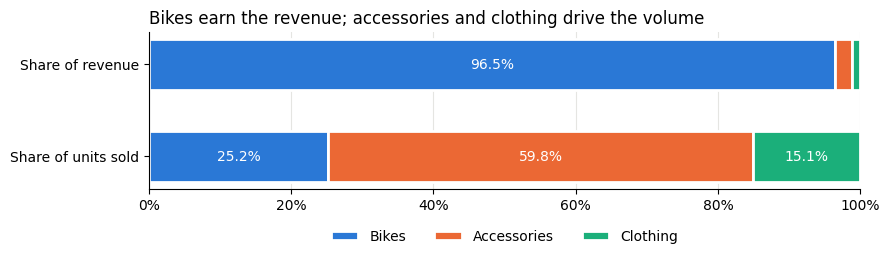

In [ ]:
fig, ax = plt.subplots(figsize=(9, 2.8))
labels = ['Share of revenue', 'Share of units sold']
left = np.zeros(2)
for c, col in zip(['Bikes', 'Accessories', 'Clothing'], [BLUE, ORANGE, AQUA]):
    vals = np.array([cat.loc[c, 'Revenue share (%)'], cat.loc[c, 'Unit share (%)']])
    ax.barh(labels, vals, left=left, color=col, edgecolor='white', linewidth=2, label=c, height=0.55)
    for y, (v, l) in enumerate(zip(vals, left)):
        if v > 6:
            ax.text(l + v / 2, y, f'{v:.1f}%', ha='center', va='center', color='white', fontsize=10)
    left += vals
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.grid(axis='y', visible=False)
ax.set_title('Bikes earn the revenue; accessories and clothing drive the volume')
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig('figures/fig2_category_share.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Question 4 - Does owning a home make a difference in sales?

The comparison is made per customer (`HouseOwnerFlag` 1 = owns a home). I compare revenue per customer,
orders per customer, and the share who bought a bike. I use Welch's t-test (unequal group sizes and spreads)
with a Mann-Whitney U test as a check, because spending is highly skewed, and Cohen's d for the size of the gap.

In [ ]:
own, rent = customers[customers.HouseOwner == 1], customers[customers.HouseOwner == 0]
q4 = pd.DataFrame({
    'Customers': [len(own), len(rent)],
    'Share of customers (%)': [len(own) / len(customers) * 100, len(rent) / len(customers) * 100],
    'Share of revenue (%)': [own.Revenue.sum() / customers.Revenue.sum() * 100, rent.Revenue.sum() / customers.Revenue.sum() * 100],
    'Revenue per customer': [own.Revenue.mean(), rent.Revenue.mean()],
    'Median revenue': [own.Revenue.median(), rent.Revenue.median()],
    'Orders per customer': [own.Orders.mean(), rent.Orders.mean()],
    'Bought a bike (%)': [own.BikeBuyer.mean() * 100, rent.BikeBuyer.mean() * 100],
    'Mean yearly income': [own.YearlyIncome.mean(), rent.YearlyIncome.mean()],
    'Mean children': [own.TotalChildren.mean(), rent.TotalChildren.mean()],
}, index=['Homeowner', 'Non-homeowner'])

t = stats.ttest_ind(own.Revenue, rent.Revenue, equal_var=False)
u = stats.mannwhitneyu(own.Revenue, rent.Revenue)
chi = stats.chi2_contingency(pd.crosstab(customers.HouseOwner, customers.BikeBuyer))
diff = own.Revenue.mean() - rent.Revenue.mean()
print(f'Revenue per customer difference: ${diff:,.2f} ({diff / rent.Revenue.mean() * 100:.1f}% higher for homeowners)')
print(f'Welch t = {t.statistic:.2f}, p {fmt_p(t.pvalue)} | Mann-Whitney p {fmt_p(u.pvalue)} | Cohen\'s d = {cohens_d(own.Revenue, rent.Revenue):.3f}')
print(f'Bike purchase rate: chi-square p = {chi[1]:.3f}')
q4.round(2)

Revenue per customer difference: $130.51 (8.7% higher for homeowners)
Welch t = 3.98, p < .001 | Mann-Whitney p < .001 | Cohen's d = 0.061
Bike purchase rate: chi-square p = 0.316


,Customers,Share of customers (%),Share of revenue (%),Revenue per customer,Median revenue,Orders per customer,Bought a bike (%),Mean yearly income,Mean children
Homeowner,12502,67.64,69.44,"1,630.57",342.00,1.52,49.66,"58,326.67",2.05
Non-homeowner,5982,32.36,30.56,"1,500.05",209.96,1.44,48.86,"55,172.18",1.41


In [ ]:
# Does the difference hold within each market?
rows = []
for country, g in customers.groupby('Country'):
    o, r = g.loc[g.HouseOwner == 1, 'Revenue'], g.loc[g.HouseOwner == 0, 'Revenue']
    rows.append({'Country': country, 'Homeowner share (%)': len(o) / len(g) * 100,
                 'Homeowner $/customer': o.mean(), 'Non-homeowner $/customer': r.mean(),
                 'Difference ($)': o.mean() - r.mean(), 'Difference (%)': (o.mean() / r.mean() - 1) * 100,
                 'Welch p': stats.ttest_ind(o, r, equal_var=False).pvalue, "Cohen's d": cohens_d(o, r)})
q4_country = pd.DataFrame(rows).set_index('Country')

customers['Market'] = np.where(customers.Country.isin(['France', 'Germany', 'United Kingdom']),
                               'Europe (FR, DE, UK)', 'Other (AU, CA, US)')
rows = []
for mkt, g in customers.groupby('Market'):
    o, r = g.loc[g.HouseOwner == 1, 'Revenue'], g.loc[g.HouseOwner == 0, 'Revenue']
    rows.append({'Market': mkt, 'Homeowner $/customer': o.mean(), 'Non-homeowner $/customer': r.mean(),
                 'Difference (%)': (o.mean() / r.mean() - 1) * 100,
                 'Welch p': stats.ttest_ind(o, r, equal_var=False).pvalue, "Cohen's d": cohens_d(o, r)})
display(q4_country.round(3)); display(pd.DataFrame(rows).set_index('Market').round(3))

,Homeowner share (%),Homeowner $/customer,Non-homeowner $/customer,Difference ($),Difference (%),Welch p,Cohen's d
Country,,,,,,,
Australia,63.74,"2,536.09","2,500.68",35.42,1.42,0.69,0.01
Canada,67.22,"1,316.04","1,141.96",174.08,15.24,0.05,0.10
France,64.97,"1,699.16","1,018.62",680.55,66.81,0.00,0.30
Germany,66.18,"1,806.90","1,272.06",534.84,42.05,0.00,0.24
United Kingdom,66.34,"1,928.59","1,466.36",462.22,31.52,0.00,0.20
United States,70.78,"1,195.59","1,213.75",-18.16,-1.50,0.66,-0.01


,Homeowner $/customer,Non-homeowner $/customer,Difference (%),Welch p,Cohen's d
Market,,,,,
"Europe (FR, DE, UK)","1,814.55","1,253.15",44.80,0.00,0.25
"Other (AU, CA, US)","1,555.49","1,613.21",-3.58,0.14,-0.03


In [ ]:
# Homeowners differ in income, children, etc. A regression holds those constant (robust HC1 standard errors).
model = smf.ols('Revenue ~ HouseOwner + C(YearlyIncome) + C(Country) + TotalChildren + C(CarsOwned)'
                ' + C(MaritalStatus) + C(Gender) + C(Education)', data=customers).fit(cov_type='HC1')
print(f"Adjusted homeowner difference: ${model.params['HouseOwner']:,.2f} per customer "
      f"(SE {model.bse['HouseOwner']:,.2f}, p {fmt_p(model.pvalues['HouseOwner'])}); R-squared = {model.rsquared:.3f}")

# Interaction model: Market replaces Country here (Country would be collinear with Market)
inter = smf.ols('Revenue ~ HouseOwner * Market + C(YearlyIncome) + TotalChildren + C(CarsOwned)'
                ' + C(MaritalStatus) + C(Gender) + C(Education)', data=customers).fit(cov_type='HC1')
term = [k for k in inter.params.index if k.startswith('HouseOwner:')][0]
print(f"Homeowner effect in Europe (FR, DE, UK): ${inter.params['HouseOwner']:,.2f} (p {fmt_p(inter.pvalues['HouseOwner'])})")
print(f"Change in the homeowner effect outside Europe: ${inter.params[term]:,.2f} (p {fmt_p(inter.pvalues[term])})")
outside = inter.t_test(f'HouseOwner + {term} = 0')
print(f"Implied homeowner effect outside Europe: ${float(np.squeeze(outside.effect)):,.2f} "
      f"(p {fmt_p(float(np.squeeze(outside.pvalue)))})")

Adjusted homeowner difference: $231.15 per customer (SE 33.36, p < .001); R-squared = 0.127
Homeowner effect in Europe (FR, DE, UK): $597.61 (p < .001)
Change in the homeowner effect outside Europe: $-547.27 (p < .001)
Implied homeowner effect outside Europe: $50.34 (p = 0.196)


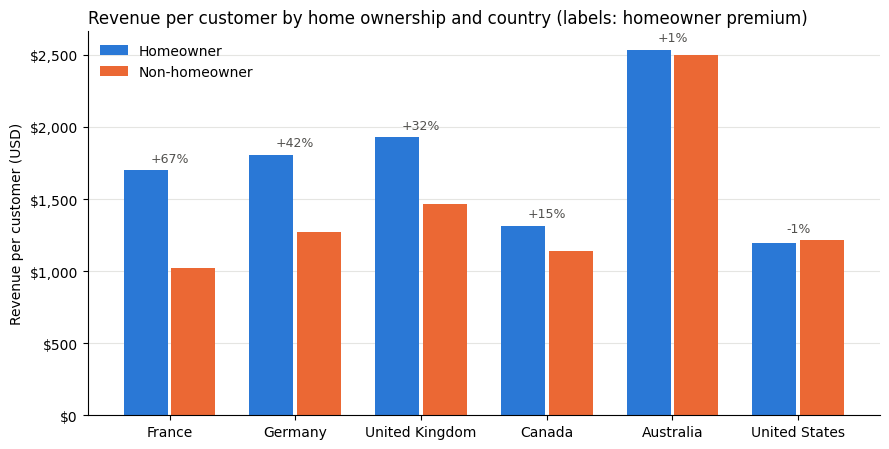

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = q4_country.sort_values('Difference (%)', ascending=False).index
x = np.arange(len(order)); w = 0.38
b1 = ax.bar(x - w / 2, q4_country.loc[order, 'Homeowner $/customer'], w - 0.03, color=BLUE, label='Homeowner')
b2 = ax.bar(x + w / 2, q4_country.loc[order, 'Non-homeowner $/customer'], w - 0.03, color=ORANGE, label='Non-homeowner')
for xi, c in zip(x, order):
    pct = q4_country.loc[c, 'Difference (%)']
    top_y = q4_country.loc[c, ['Homeowner $/customer', 'Non-homeowner $/customer']].max()
    ax.text(xi, top_y + 60, f'{pct:+.0f}%', ha='center', fontsize=9, color=GREY_TEXT)
ax.set_xticks(x, order)
ax.yaxis.set_major_formatter(usd_plain)
ax.set_ylabel('Revenue per customer (USD)')
ax.set_title('Revenue per customer by home ownership and country (labels: homeowner premium)')
ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('figures/fig3_homeowner_country.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Additional analysis to support a growth strategy

### 7.1 Monthly trend and product launches

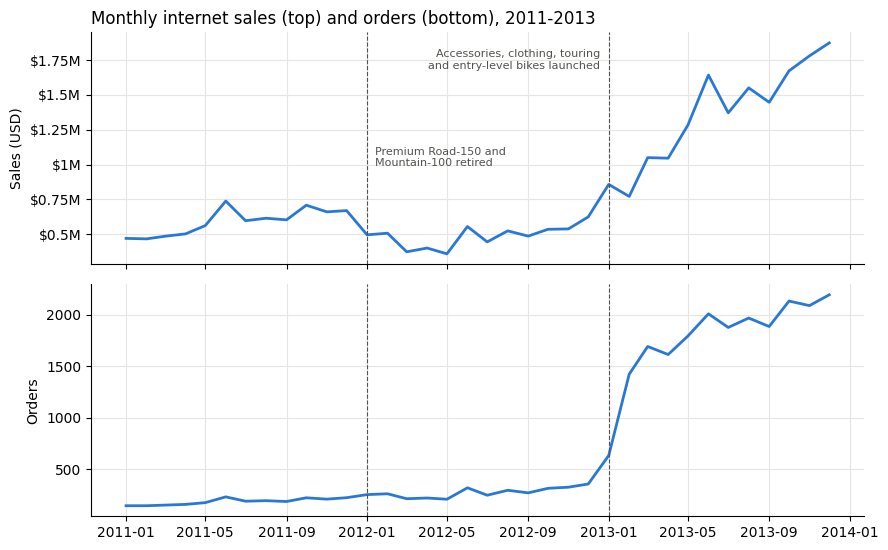

,Revenue,Orders,Customers,BikesSold,Avg order value,Avg bike price
OrderYear,,,,,,
2011,"7,075,525.93",2216,2216,2216,"3,192.93","3,192.93"
2012,"5,842,485.20",3269,3255,3269,"1,787.24","1,786.39"
2013,"16,351,550.34",21289,17429,9706,768.08,"1,582.48"


In [ ]:
monthly = (sales[(sales.OrderDate >= '2011-01-01') & (sales.OrderDate < '2014-01-01')]
           .set_index('OrderDate').resample('MS')
           .agg({'SalesAmount': 'sum', 'SalesOrderNumber': 'nunique'}))
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
axes[0].plot(monthly.index, monthly.SalesAmount, color=BLUE, lw=2)
axes[0].yaxis.set_major_formatter(usd); axes[0].set_ylabel('Sales (USD)')
axes[0].set_title('Monthly internet sales (top) and orders (bottom), 2011-2013')
axes[1].plot(monthly.index, monthly.SalesOrderNumber, color=BLUE, lw=2)
axes[1].set_ylabel('Orders')
for a in axes:
    for d in ['2012-01-01', '2013-01-01']:
        a.axvline(pd.Timestamp(d), color=GREY_TEXT, lw=0.8, ls='--')
axes[0].annotate('Premium Road-150 and\nMountain-100 retired', xy=(pd.Timestamp('2012-01-01'), 1.05e6),
                 xytext=(6, 0), textcoords='offset points', fontsize=8, color=GREY_TEXT, va='center')
axes[0].annotate('Accessories, clothing, touring\nand entry-level bikes launched', xy=(pd.Timestamp('2013-01-01'), 1.75e6),
                 xytext=(-6, 0), textcoords='offset points', fontsize=8, color=GREY_TEXT, va='center', ha='right')
fig.tight_layout()
fig.savefig('figures/fig4_monthly_trend.png', dpi=200, bbox_inches='tight')
plt.show()

yearly = sales[sales.OrderYear.between(2011, 2013)].groupby('OrderYear').agg(
    Revenue=('SalesAmount', 'sum'), Orders=('SalesOrderNumber', 'nunique'), Customers=('CustomerKey', 'nunique'),
    BikesSold=('Category', lambda s: (s == 'Bikes').sum()))
yearly['Avg order value'] = yearly.Revenue / yearly.Orders
yearly['Avg bike price'] = sales[(sales.Category == 'Bikes')].groupby('OrderYear').UnitPrice.mean()
yearly.round(2)

In [ ]:
# Bike line-up by year: which models were on sale and what they earned
lineup = sales[sales.Category == 'Bikes'].pivot_table(index='Model', columns='OrderYear', values='SalesAmount',
                                                      aggfunc='sum', fill_value=0)
lineup['Avg price'] = sales[sales.Category == 'Bikes'].groupby('Model').UnitPrice.mean()
lineup.sort_values('Avg price', ascending=False).round(0)

OrderYear,2010,2011,2012,2013,Avg price
Model,,,,,
Road-150,"25,048.00","5,524,849.00",0.00,0.00,"3,578.00"
Mountain-100,"16,975.00","1,324,146.00",0.00,0.00,"3,387.00"
Touring-1000,0.00,0.00,"14,304.00","2,977,703.00","2,384.00"
Road-250,0.00,"34,294.00","2,718,838.00","1,698,128.00","2,339.00"
Mountain-200,0.00,"8,219.00","2,261,546.00","5,659,710.00","2,232.00"
Road-350-W,0.00,0.00,"8,505.00","1,571,715.00","1,701.00"
Touring-2000,0.00,0.00,"4,859.00","447,065.00","1,215.00"
Road-550-W,0.00,"2,001.00","359,637.00","1,152,984.00","1,090.00"
Mountain-400-W,0.00,0.00,769.00,"417,064.00",769.00


### 7.2 Customers and baskets

In [ ]:
seg = customers.groupby('BikeBuyer').agg(Customers=('Revenue', 'size'), Revenue=('Revenue', 'sum'),
                                         RevenuePerCustomer=('Revenue', 'mean'), Orders=('Orders', 'mean'),
                                         Income=('YearlyIncome', 'mean'))
seg.index = seg.index.map({True: 'Bought a bike', False: 'Accessories/clothing only'})
seg['Share of customers (%)'] = seg.Customers / seg.Customers.sum() * 100
seg['Share of revenue (%)'] = seg.Revenue / seg.Revenue.sum() * 100
display(seg.round(2))

# 2013 baskets: how often does a bike order include an add-on?
o13 = (sales[sales.OrderYear == 2013].groupby('SalesOrderNumber')
       .agg(HasBike=('Category', lambda s: (s == 'Bikes').any()),
            HasAddOn=('Category', lambda s: (s != 'Bikes').any()), Value=('SalesAmount', 'sum')))
basket = o13.groupby(['HasBike', 'HasAddOn']).agg(Orders=('Value', 'size'), AvgValue=('Value', 'mean'), Revenue=('Value', 'sum'))
print(f"2013: {o13.HasBike.sum():,} orders contained a bike; {o13.loc[o13.HasBike, 'HasAddOn'].mean()*100:.1f}% of them also contained an accessory or clothing item.")
print(f"2013: {(~o13.HasBike).sum():,} orders ({(~o13.HasBike).mean()*100:.1f}%) contained no bike.")
display(basket.round(2))

# Did earlier bike buyers come back once accessories were available?
launch = sales.loc[sales.Category != 'Bikes', 'OrderDate'].min()
early_bike = sales[(sales.Category == 'Bikes') & (sales.OrderDate < launch)].CustomerKey.unique()
returned = sales[(sales.CustomerKey.isin(early_bike)) & (sales.OrderDate >= launch)].CustomerKey.nunique()
print(f'Accessories first sold on {launch.date()}. Of {len(early_bike):,} customers who bought a bike before then, '
      f'{returned:,} ({returned/len(early_bike)*100:.1f}%) placed another order afterwards.')

,Customers,Revenue,RevenuePerCustomer,Orders,Income,Share of customers (%),Share of revenue (%)
BikeBuyer,,,,,,,
Accessories/clothing only,9352,"632,495.14",67.63,1.33,"55,916.38",50.60,2.15
Bought a bike,9132,"28,726,182.08","3,145.66",1.67,"58,728.65",49.40,97.85


2013: 9,706 orders contained a bike; 87.6% of them also contained an accessory or clothing item.
2013: 11,583 orders (54.4%) contained no bike.


Orders  AvgValue       Revenue
HasBike HasAddOn                                
False   True       11583     50.66    586,800.42
True    False       1205  1,533.47  1,847,826.27
        True        8501  1,637.09 13,916,923.65

Accessories first sold on 2012-12-28. Of 5,428 customers who bought a bike before then, 4,922 (90.7%) placed another order afterwards.


In [ ]:
mkt = customers.groupby('Country').agg(Customers=('Revenue', 'size'), Revenue=('Revenue', 'sum'),
                                        RevenuePerCustomer=('Revenue', 'mean'),
                                        AccessoryOnlyShare=('BikeBuyer', lambda s: (1 - s.mean()) * 100),
                                        OrdersPerCustomer=('Orders', 'mean'))
mkt['Share of customers (%)'] = mkt.Customers / mkt.Customers.sum() * 100
mkt['Share of revenue (%)'] = mkt.Revenue / mkt.Revenue.sum() * 100
mkt['Sales growth 2012->2013 (x)'] = q1_growth['2013 sales / 2012 sales (x)']
mkt.sort_values('Revenue', ascending=False).round(2)

,Customers,Revenue,RevenuePerCustomer,AccessoryOnlyShare,OrdersPerCustomer,Share of customers (%),Share of revenue (%),Sales growth 2012->2013 (x)
Country,,,,,,,,
United States,7819,"9,389,789.51","1,200.89",54.35,1.22,42.30,31.98,3.80
Australia,3591,"9,061,000.58","2,523.25",39.99,1.87,19.43,30.86,2.04
United Kingdom,1913,"3,391,712.21","1,772.98",46.05,1.58,10.35,11.55,2.98
Germany,1780,"2,894,312.34","1,626.02",49.21,1.40,9.63,9.86,2.89
France,1810,"2,644,017.71","1,460.78",54.92,1.37,9.79,9.01,2.44
Canada,1571,"1,977,844.86","1,258.97",58.24,2.15,8.50,6.74,3.53


### 7.3 Sizing the opportunity

A simple scenario: what if a share of the accessory-only customers bought one bike at the 2013 average bike price?
This is an illustration of scale, not a forecast.

In [ ]:
acc_only = (~customers.BikeBuyer).sum()
bike_price_2013 = sales[(sales.Category == 'Bikes') & (sales.OrderYear == 2013)].UnitPrice.mean()
margin_rate_bikes = cat.loc['Bikes', 'Gross margin (%)'] / 100
rev_2013 = q1.loc['Total', 2013]
scen = pd.DataFrame({'Conversion rate': [0.05, 0.10, 0.15]})
scen['New bike buyers'] = (scen['Conversion rate'] * acc_only).round()
scen['Added revenue'] = scen['New bike buyers'] * bike_price_2013
scen['Added gross margin'] = scen['Added revenue'] * margin_rate_bikes
scen['% of 2013 sales'] = scen['Added revenue'] / rev_2013 * 100
print(f'Accessory-only customers: {acc_only:,} | 2013 average bike price: ${bike_price_2013:,.2f} | bike gross margin: {margin_rate_bikes*100:.1f}%')
scen.round(2)

Accessory-only customers: 9,352 | 2013 average bike price: $1,582.48 | bike gross margin: 40.6%


,Conversion rate,New bike buyers,Added revenue,Added gross margin,% of 2013 sales
0,0.05,468.00,"740,598.30","300,908.60",4.53
1,0.10,935.00,"1,479,614.13","601,174.24",9.05
2,0.15,"1,403.00","2,220,212.43","902,082.84",13.58


## 8. Summary of findings

* **Q1.** Internet sales were \$7.08M in 2011, fell 17.4% to \$5.84M in 2012, and rose 179.9% to \$16.35M in 2013.
  The United States (\$9.39M) and Australia (\$9.06M) account for 62.9% of all sales. The UK, Germany, and France were the only
  markets that grew in 2012, and they grew 3.4-3.9x between 2011 and 2013, against 1.7-2.2x for the other three.
* **Q2.** Customers' mean yearly income is \$57,306 (SD \$32,286; min \$10,000; max \$170,000). Income differs by country
  (Australia \$64,339 and the US \$63,617 are highest; France \$35,762 is lowest; eta squared = .091) but not by gender:
  in no country is the male-female gap significant (all p > .05, |d| <= 0.06).
* **Q3.** Bikes generate 96.5% of revenue. The average selling price of a bike is **\$1,862.42** (median \$2,071.42);
  the unweighted average across the 88 bike products is \$1,599.06. The average bike price fell from \$3,193 in 2011 to \$1,582 in 2013.
* **Q4.** Overall, homeowners spend \$131 (8.7%) more per customer, a statistically significant but negligible difference (d = 0.06).
  The difference is concentrated in Europe (+44.8%, d = 0.25) and is absent in Australia and the United States.
* **Strategy.** Half of all customers (9,352) have bought only accessories or clothing and generate 2.2% of revenue.
  Converting them into bike buyers, through the entry-level bikes and the accessory relationship, is the largest growth lever.